# Mixed boundary conditions and grid refinement

A ghost point enforces the zero derivative at the right boundary.

$$y''+4y=4x,\quad y(0)=0,\quad y'(\pi/2)=0,\qquad y=x+\tfrac12\sin(2x).$$

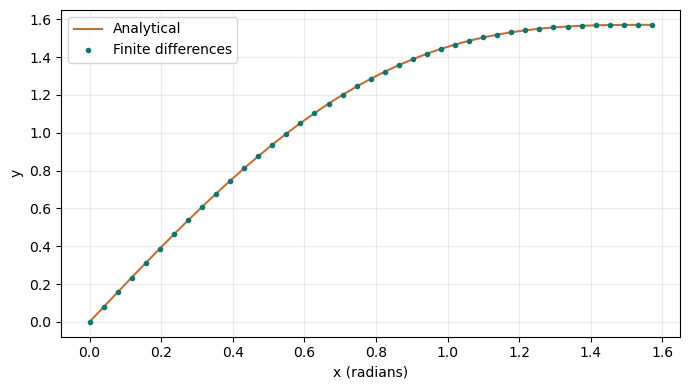

Grid intervals: [10, 20, 40, 80]
Maximum errors: [0.00682963 0.00167636 0.00041719 0.00010418]


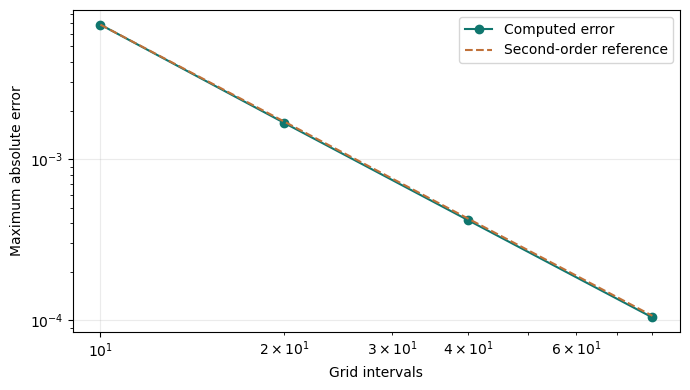

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def solve_bvp(n):
    x = np.linspace(0, np.pi/2, n+1)
    h = x[1]-x[0]
    A = np.zeros((n+1, n+1))
    b = 4*h*h*x
    A[0, 0] = 1
    b[0] = 0
    for i in range(1, n):
        A[i, i-1:i+2] = [1, -2+4*h*h, 1]
    A[-1, -2:] = [2, -2+4*h*h]
    return x, np.linalg.solve(A, b)

exact = lambda x: x + .5*np.sin(2*x)
x, y = solve_bvp(40)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(x, exact(x), color='#c07139', label='Analytical')
ax.plot(x, y, 'o', color='#0f766e', markersize=3, label='Finite differences')
ax.set(xlabel='x (radians)', ylabel='y')
ax.legend()
ax.grid(alpha=.25)
plt.tight_layout()
plt.show()
assert abs(y[0]) < 1e-12
assert np.max(np.abs(y-exact(x))) < .002

sizes = [10, 20, 40, 80]
errors = []
for n in sizes:
    x, y = solve_bvp(n)
    errors.append(np.max(np.abs(y-exact(x))))
print('Grid intervals:', sizes)
print('Maximum errors:', np.round(errors, 8))
assert np.all(np.diff(errors) < 0)
fig, ax = plt.subplots(figsize=(7, 4))
ax.loglog(sizes, errors, 'o-', color='#0f766e', label='Computed error')
ax.loglog(sizes, errors[0]*(sizes[0]/np.array(sizes))**2, '--', color='#c07139', label='Second-order reference')
ax.set(xlabel='Grid intervals', ylabel='Maximum absolute error')
ax.legend()
ax.grid(alpha=.25)
plt.tight_layout()
plt.show()